In [1]:
from PhaseEstimation.inputs import Diag, Brick, Mps # noqa
from PhaseEstimation.ad.model import Ad
from PhaseEstimation.ad.train import train
from PhaseEstimation.ad.plot import loss_curve, compress

In [2]:
path = "./data/L8_s20_diag"

In [3]:
path = "/home/samonaco/dust/Quantum-Phase-Detection-ANNNI/study/L8_chi64_side20/data"

In [4]:
inputclass = Brick(path, "brick10")
print(inputclass)

Input Class (Brick):
  N        : 8
  side     : 20


In [5]:
autoencoder = Ad(inputclass, num_trashwires=3, depth=2)

In [6]:
autoencoder

Anomaly Detection Class:
  num_qubits : 8
  side       : 20
  num_params : 19

In [7]:
autoencoder.show()

0: ────────────────────────────────────────────╭U(M12)─╭U(M16)─────────╭U(M22)─╭U(M16)────────
1: ────────────────────────────────────╭U(M9)──╰U(M12)─╰U(M16)─╭U(M19)─╰U(M22)─╰U(M16)─╭U(M27)
2: ─────────────────────────────╭U(M6)─╰U(M9)──╭U(M13)─────────╰U(M19)─╭U(M23)─────────╰U(M27)
3: ──────────────────────╭U(M4)─╰U(M6)─╭U(M10)─╰U(M13)─╭U(M17)─────────╰U(M23)─╭U(M25)────────
4: ───────────────╭U(M2)─╰U(M4)─╭U(M7)─╰U(M10)─╭U(M14)─╰U(M17)─╭U(M20)─────────╰U(M25)─╭U(M28)
5: ────────╭U(M1)─╰U(M2)─╭U(M5)─╰U(M7)─╭U(M11)─╰U(M14)─╭U(M18)─╰U(M20)─╭U(M24)─────────╰U(M28)
6: ─╭U(M0)─╰U(M1)─╭U(M3)─╰U(M5)─╭U(M8)─╰U(M11)─╭U(M15)─╰U(M18)─╭U(M21)─╰U(M24)─╭U(M26)────────
7: ─╰U(M0)────────╰U(M3)────────╰U(M8)─────────╰U(M15)─────────╰U(M21)─────────╰U(M26)────────

──╭U(M29)─╭U(M32)─────────╭U(M37)─╭U(M32)─────────╭U(M44)─╭U(M32)─────────╭U(M51)─╭U(M16)────────
──╰U(M29)─╰U(M32)─╭U(M35)─╰U(M37)─╰U(M32)─╭U(M42)─╰U(M44)─╰U(M32)─╭U(M49)─╰U(M51)─╰U(M16)─╭U(M56)
──╭U(M30)─────────╰U(M35)─╭U(M38)─────────╰

In [8]:
loss_value, params, loss_history, params_history = train(
    autoencoder,
    num_epochs = 200,
    lr = 0.05,
    k= 0,
    h = 0,
    R = 0,
    path = "./data/ad",
)

COST: 0.0005: 100%|██████████| 200/200 [00:06<00:00, 33.32it/s] 


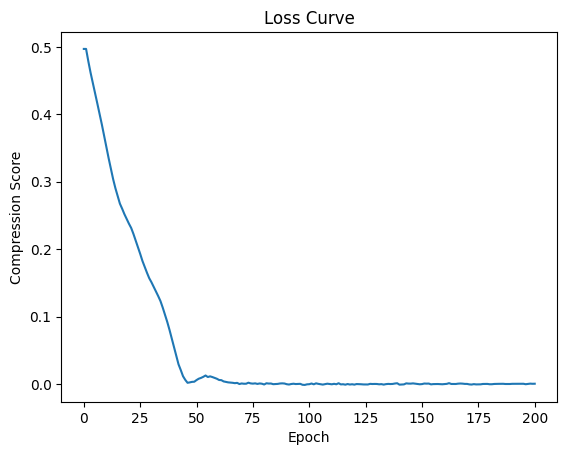

In [9]:
loss_curve(loss_history, "./data/ad")

In [10]:
compression = autoencoder.v_compress(params)

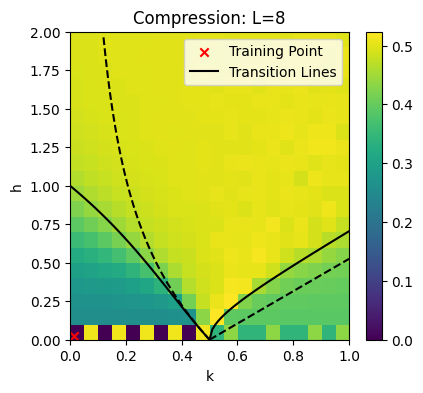

In [11]:
compress(compression, autoencoder.num_qubits, [[0,0]], "./data/ad")